# Smart Irrigation — irrigation recommendation prototype

**Status: exploratory physics-based decision support, not a validated ML irrigation classifier or live controller.** Historical source covers March 2024–October 2025. These predictions cannot be used to turn watering systems on/off.

Why this approach? The input has no farm-verified irrigation actions. Unlike the demonstration `sm_clean(t+24h) < 70` proxy, this notebook uses **crop, root depth and a provisional FAO-56 root-zone depletion trigger**. It deliberately marks uncertainty. No real decision labels are created.

## 1. Physics of the decision

For soil volumetric water content θ (m³/m³), **assumed** field capacity θFC, wilting point θWP, root depth Zr, and depletion fraction p:

- `TAW = 1000 × (θFC − θWP) × Zr` (mm)
- `RAW = p × TAW` (mm)
- `Dr = clip(1000 × (θFC − θSMAP) × Zr, 0, TAW)` (mm)
- `ETc ≈ Kc × ET0` and `p ≈ clip(p_base + 0.04 × (5 − ETc_24h), 0.1, 0.8)`

A nominal candidate appears if `Dr >= RAW`. A nominally adequate state requires less water deficit than RAW. This follows the general FAO-56 approach, but **the supplied sensors have no validated field capacity/wilting point measurements**.

**Critical limitations:** SMAP L4 root-zone moisture is not a field probe; sensor moisture is on an unrelated uncalibrated 0–100 scale; loam classification and 0.25/0.12 FC/PWP are approximate values from the team's analysis notebook; and crop planting dates and root depth are illustrative. Historic ERA5 observations are NOT used as future weather forecasts.

Reference: [FAO-56 Chapter 8 — Soil water balance](https://www.fao.org/4/x0490e/x0490e0e.htm).

## 2. Load reproduced outputs

Run `python irrigation_recommendations.py --data input/irrigation_ml_dataset.csv` from the project directory to regenerate. The included CSV is already calculated from the attached dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

source = Path("outputs/decision_prototype_daily.csv")
decisions = pd.read_csv(source, parse_dates=["decision_timestamp"])
print("Rows:", len(decisions), "Fields:", decisions.field_id.nunique())
print("Period:", decisions.decision_timestamp.min(), "to", decisions.decision_timestamp.max())
display(decisions.head(3))

Rows: 1160 Fields: 2
Period: 2024-03-08 06:00:00 to 2025-10-12 06:00:00


,field_id,decision_timestamp,crop,soil_class_coarse,in_assumed_growing_season,smap_theta_rootzone_m3m3,smap_age_hours,sensor_moisture_raw,battery_voltage,sensor_valid_indicator,kc_assumed,root_depth_m_assumed,et0_past24h_mm,etc_past24h_mm,depletion_fraction_p,fc_assumed_m3m3,pwp_assumed_m3m3,taw_mm,raw_mm,depletion_mm,depletion_over_raw,theta_trigger_nominal,theta_trigger_min_sensitivity,theta_trigger_max_sensitivity,assumption_robustness,nominal_action,recommendation,confidence,reason,forecast_used,rain_forecast_next24h_mm,et0_forecast_next24h_mm,validated_irrigation_label
0,field_3334,2024-03-08 06:00:00,sorghum,loam,False,0.331375,1.5,0.8,4.1,False,NaN,NaN,NaN,NaN,0.55,0.25,0.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_assessed,unknown,no_action_out_of_season,very_low,outside ASSUMED crop calendar,False,NaN,NaN,False
1,field_3334,2024-03-09 06:00:00,sorghum,loam,False,0.334609,1.5,0.8,4.1,False,NaN,NaN,NaN,NaN,0.55,0.25,0.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_assessed,unknown,no_action_out_of_season,very_low,outside ASSUMED crop calendar,False,NaN,NaN,False
2,field_3334,2024-03-10 06:00:00,sorghum,loam,False,0.333448,1.5,0.8,4.1,False,NaN,NaN,NaN,NaN,0.55,0.25,0.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_assessed,unknown,no_action_out_of_season,very_low,outside ASSUMED crop calendar,False,NaN,NaN,False


## 3. Historical decision distribution

`review_irrigation` means **ask a specialist to check** whether irrigation might be needed, not an automatic `irrigate` action. `monitor` includes decisions sensitive to soil assumptions. `no_action_out_of_season` is based on an **assumed calendar**, not known sowing/harvest dates.

recommendation,insufficient_data,monitor,no_action,no_action_out_of_season,review_irrigation
field_id,,,,,
field_3334,1,52,261,270,0
field_3335,21,189,78,227,61


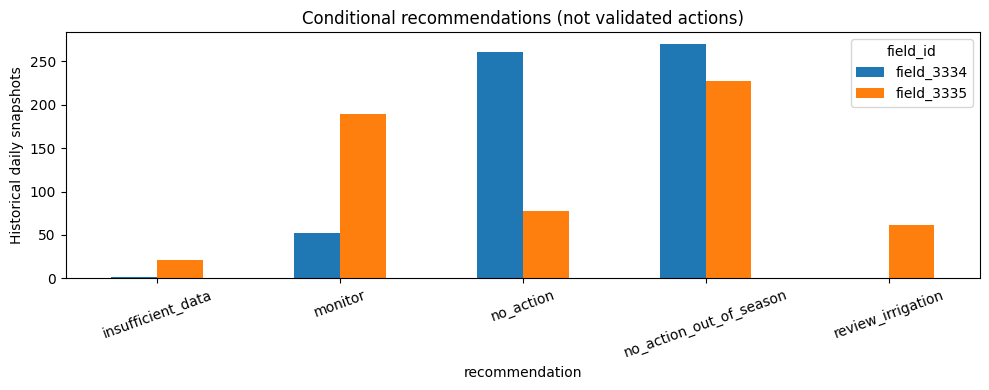

In [2]:
counts = pd.crosstab(decisions.field_id, decisions.recommendation)
display(counts)
ax = counts.T.plot(kind="bar", figsize=(10, 4), rot=20)
ax.set_ylabel("Historical daily snapshots")
ax.set_title("Conditional recommendations (not validated actions)")
plt.tight_layout()
plt.show()

## 4. Are the decisions robust to reasonable changes in soil assumptions?

Only `wet_all_assumptions` and `dry_all_assumptions` would agree across the wide FC/PWP reference interval. A decision marked `assumption_sensitive` could change when the physical soil properties are measured.

In [3]:
display(pd.crosstab(decisions.recommendation, decisions.assumption_robustness))
print("Potential irrigation cases:", (decisions.recommendation == "review_irrigation").sum())
print("Potential cases with assumption uncertainty:",
      ((decisions.recommendation == "review_irrigation") & (decisions.assumption_robustness == "assumption_sensitive")).sum())

assumption_robustness,assumption_sensitive,not_assessed,wet_all_assumptions
recommendation,,,
insufficient_data,0,22,0
monitor,241,0,0
no_action,0,0,339
no_action_out_of_season,0,497,0
review_irrigation,61,0,0


Potential irrigation cases: 61
Potential cases with assumption uncertainty: 61


## 5. Inspect examples during the growing season

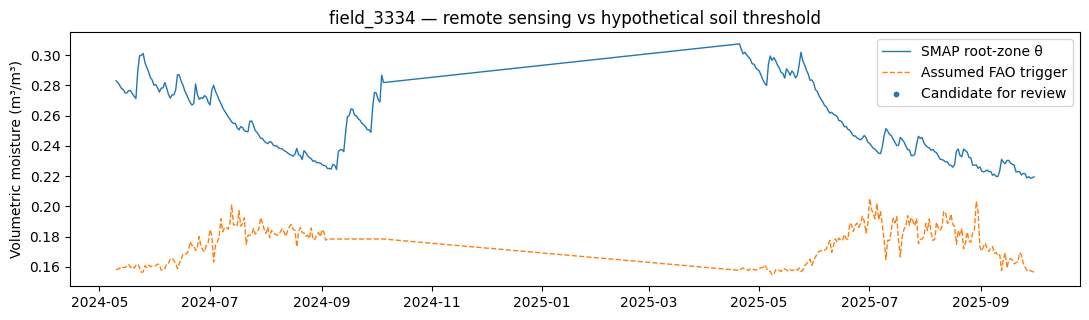

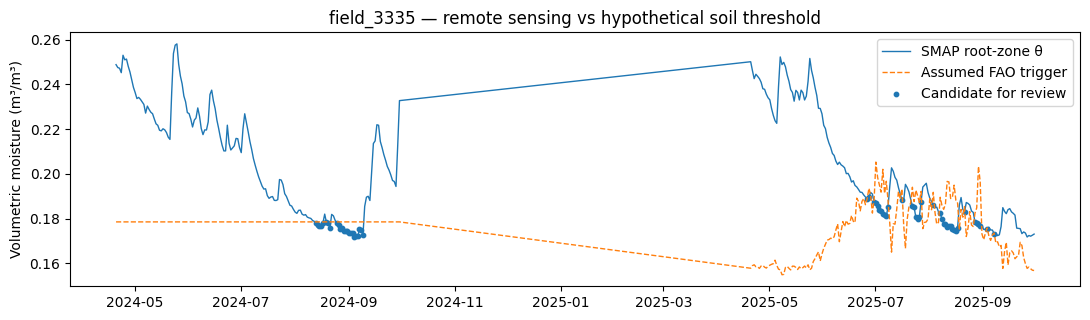

In [4]:
for fid, g in decisions.groupby("field_id"):
    g = g[g.in_assumed_growing_season].copy().sort_values("decision_timestamp")
    fig, ax = plt.subplots(figsize=(11, 3.3))
    ax.plot(g.decision_timestamp, g.smap_theta_rootzone_m3m3, linewidth=1, label="SMAP root-zone θ")
    ax.plot(g.decision_timestamp, g.theta_trigger_nominal, linewidth=1, linestyle="--", label="Assumed FAO trigger")
    stress = g[g.nominal_action == "irrigate_candidate"]
    ax.scatter(stress.decision_timestamp, stress.smap_theta_rootzone_m3m3, s=10, label="Candidate for review")
    ax.set_title(f"{fid} — remote sensing vs hypothetical soil threshold")
    ax.set_ylabel("Volumetric moisture (m³/m³)")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 6. Forecasts and `postpone`

A decision to postpone due to upcoming rain requires **actual archived forecasts** issued before the decision timestamp. None were supplied, so `postpone_review` will not appear in the included results. The program supports a separate user-supplied CSV with columns `field_id, issue_time, decision_timestamp, rain_next24h_mm, et0_next24h_mm`. The issue time must be no later than the decision time and no older than 24 hours. Do not fill this file with future *observations*.

Example:
```bash
python irrigation_recommendations.py --data input/irrigation_ml_dataset.csv --forecast input/issued_forecasts.csv
```

## 7. Readiness and next steps

**What this notebook provides:** physically motivated candidate decisions, conservative confidence flags, a sensitivity test for unknown soil properties, and historical reproducibility. It is not a `LightGBMClassifier` trained against genuine watering actions, and no classification metrics are claimed.

**To reach real irrigation decision learning:** obtain field-calibrated FC/PWP, crop sowing dates and growth phase, sensor units/calibration and depth, historical irrigation event logs or agronomist-validated daily labels, irrigation hardware information, and archived issued rainfall forecasts. Retain trust indicators from the DE pipeline. Then train/evaluate the supervised decision model using walk-forward validation on the measured decisions and quantify false negatives; compare it with this provisional water-balance baseline.

**Do not use the last historical decision as today's recommendation:** attached telemetry ends in October 2025, while today is October 2026.